# TP3 - Regressão e transição para classificação
Fintech Guard | Integrante A - Dados e IA | 14/10/2026

## 1. Pergunta e protocolo anterior à execução
Até que ponto medidas lexicais aproximam a quantidade de caracteres de uma mensagem?
Experimento pedagógico obrigatório; não é um modelo de fraude nem um classificador de intenções.
O alvo é `n_chars`. Modelo simples: `n_words`; múltiplo: `n_words`, `mean_word_length`,
`uppercase_ratio`, `n_exclamations`. Referência: média do alvo no treino.
`n_links` é constante. Excluímos `digit_ratio`, cujo denominador é o próprio comprimento alvo,
os rótulos e os IDs. Não usamos produto palavras × comprimento médio nem variável que copie o alvo.
Ainda há dependência estrutural entre extensão lexical e caracteres: desempenho alto não prova utilidade operacional.

Divisão única 80/20, semente 42, estratificada por classe apenas para composição das amostras.
Imputação e escala ajustadas apenas no treino, dentro de Pipeline. Sem tuning ou escolha da semente
pelas métricas. Todos os registros foram explorados no TP2: esta avaliação interna não é um teste
externo intocado e não será apresentada como evidência de generalização do futuro classificador.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/tp3_regression.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scripts.tp3_regression import run, plot_results, partition, SIMPLE, MULTIPLE
data, features, metrics, predictions, models, protocol = run(ROOT)

## 2. Dados e pré-processamento
Mantemos as 603 mensagens limpas do TP2. A reconstrução e as 21 exclusões estão documentadas
em `reports/TP2/security_validation/`. Não removemos textos longos, não reamostramos e não
modificamos os rótulos. As funções de atributos são as mesmas do TP2.
`SimpleImputer(median) → StandardScaler → LinearRegression` é usado nos dois modelos;
a imputação é defensiva porque a validação não encontrou ausentes. A escala não é necessária
para mínimos quadrados, mas explicita a preparação e permite comparar coeficientes por desvio padrão.

In [2]:
display(data.shape)
display(data.dtypes.to_frame('tipo'))
display(data.isna().sum().to_frame('ausentes'))
display(data.describe(include='all'))
display(data.category.value_counts().to_frame('mensagens'))
display(features.describe())
display(pd.DataFrame([protocol]))

(603, 2)

,tipo
text,object
category,object


,ausentes
text,0
category,0


,text,category
count,603,603
unique,603,6
top,"You have (1) package waiting, ready for delive...",NOT-Malicious General Class
freq,1,171


,mensagens
category,
NOT-Malicious General Class,171
Phishing,110
Scareware,100
Baiting,80
Malware,77
Pretexting,65


,n_chars,n_words,mean_word_length,digit_ratio,uppercase_ratio,n_links,n_exclamations
count,603.000000,603.000000,603.000000,603.000000,603.000000,603.0,603.000000
mean,188.069652,33.008292,4.721194,0.001235,0.033652,0.0,0.064677
std,400.928435,70.727766,0.580592,0.006368,0.061838,0.0,0.265633
min,10.000000,3.000000,2.000000,0.000000,0.001337,0.0,0.000000
25%,84.000000,14.000000,4.314145,0.000000,0.017094,0.0,0.000000
50%,101.000000,17.000000,4.692308,0.000000,0.026667,0.0,0.000000
75%,134.500000,25.000000,5.129167,0.000000,0.036364,0.0,0.000000
max,3693.000000,635.000000,6.615385,0.093750,1.000000,0.0,2.000000


,seed,test_size,train_n,evaluation_n,dataset_sha256,target,simple,multiple,versions,interpretation_scope,max_chars,evaluation_max_chars,train_max_chars
0,42,0.2,482,121,b416c4362ef0447340770b7c73a57d5705ecc8bbeaf2ef...,n_chars,[n_words],"[n_words, mean_word_length, uppercase_ratio, n...","{'python': '3.13.16', 'sklearn': '1.9.1', 'pan...",Avaliação interna pedagógica; base já explorad...,3693,2960,3693


## 3. Pipeline completo: regressão simples e múltipla
Os pipelines foram ajustados pela função `run`, implementada em `scripts/tp3_regression.py`.
Os mesmos índices de treino/avaliação são usados nos três modelos. O manifesto com hash por
mensagem permite reproduzir a divisão, sem duplicar os textos nos relatórios.

In [3]:
display(models['linear_simples'][0])
display(models['linear_multipla'][0])
display(pd.DataFrame({'modelo':['simples','múltipla'], 'preditores':[SIMPLE,MULTIPLE]}))
display(pd.read_csv(ROOT/'reports/TP3/regression/coefficients.csv'))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['n_words']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['n_words','mean_word_length','uppercase_ratio','n_exclamations']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None


,modelo,preditores
0,simples,[n_words]
1,múltipla,"[n_words, mean_word_length, uppercase_ratio, n..."


,modelo,atributo,coef_por_desvio_padrao
0,linear_simples,n_words,406.750537
1,linear_multipla,n_words,408.652334
2,linear_multipla,mean_word_length,11.385069
3,linear_multipla,uppercase_ratio,-2.725138
4,linear_multipla,n_exclamations,-0.947938


## 4. R² e RMSE
R² compara o erro quadrático com a variação em torno da média do alvo da partição avaliada;
pode ser negativo. Não é acurácia de classificação. RMSE está em **caracteres** e dá maior
peso a erros grandes; não significa que toda mensagem tenha esse erro.
A referência constante usa a média do treino, portanto seu R² de avaliação não precisa ser zero.

In [4]:
display(metrics.round(4))
eval_metrics = metrics.query("particao == 'avaliacao'").set_index('modelo')
for name in eval_metrics.index:
    row=eval_metrics.loc[name]
    display(Markdown(f"**{name}:** R² = {row.r2:.4f}; RMSE = {row.rmse_caracteres:.2f} caracteres, em {int(row.n)} mensagens."))
delta=eval_metrics.loc['linear_multipla','rmse_caracteres']-eval_metrics.loc['linear_simples','rmse_caracteres']
display(Markdown(f"A diferença de RMSE (múltipla − simples) foi **{delta:.2f} caracteres**. Valor negativo favorece a múltipla nesta divisão; não demonstra superioridade em outra população. Não escolhemos um detector de ameaças a partir desse resultado."))

,modelo,particao,n,r2,rmse_caracteres
0,media_treino,treino,482,0.0000,407.3986
1,media_treino,avaliacao,121,-0.0018,372.3332
2,linear_simples,treino,482,0.9968,22.9707
3,linear_simples,avaliacao,121,0.9988,13.0514
4,linear_multipla,treino,482,0.9977,19.5069
5,linear_multipla,avaliacao,121,0.9995,8.6147


<IPython.core.display.Markdown object>

<IPython.core.display.Markdown object>

<IPython.core.display.Markdown object>

<IPython.core.display.Markdown object>

## 5. Visualizações e diagnósticos
Gráficos usam apenas as mensagens da avaliação interna. Os resíduos são observado menos previsto.
Não apagamos extremos para melhorar a aparência ou as métricas.

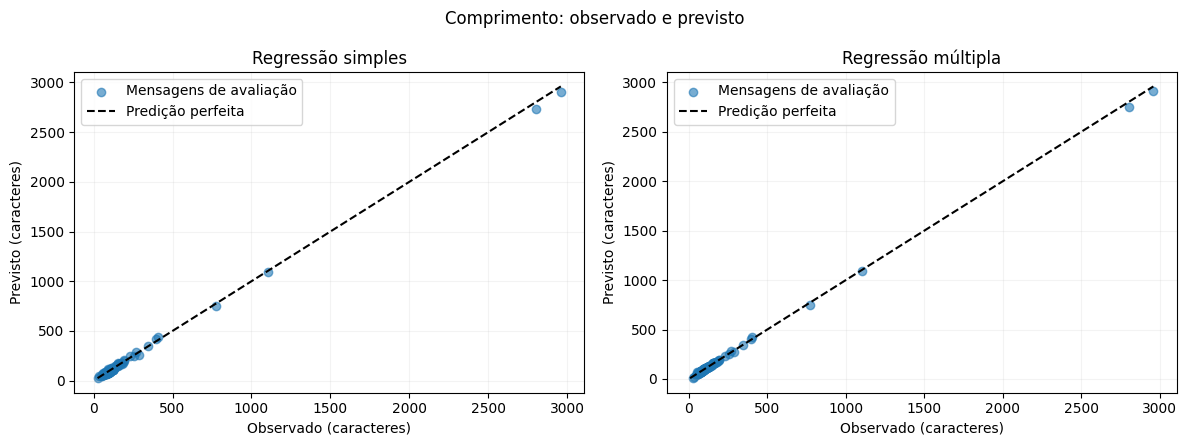

In [5]:
figures=plot_results(predictions,ROOT/'reports/TP3/figures')
plt.close('all')
display(figures[0])

**Interpretação - observado × previsto:** proximidade da diagonal indica aproximação do comprimento.
Mensagens muito longas têm grande influência na escala e no erro quadrático. Esta associação é
esperada porque palavras e caracteres medem extensão do mesmo texto; não distingue ameaça de benigno.

**Resultado observado:** os dois ajustes se aproximam da diagonal. Na avaliação de 121 mensagens, a regressão múltipla reduz o RMSE de 13,05 para 8,61 caracteres (redução de aproximadamente 34%). O R² sobe de 0,99877 para 0,99946, em uma tarefa estruturalmente redundante. Isso não significa 99,9% de acerto na identificação de ameaças.

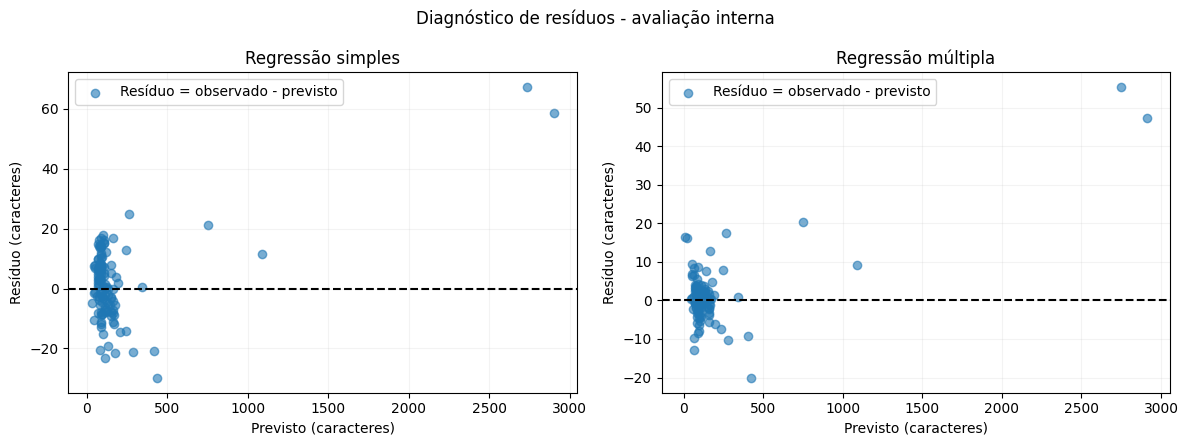

,median,std,min,max
modelo,,,,
linear_multipla,0.60,8.52,-20.16,55.36
linear_simples,1.67,12.99,-29.91,67.26
media_treino,-91.26,373.54,-166.26,2768.74


In [6]:
display(figures[1])
display(predictions.groupby('modelo').residuo.agg(['median','std','min','max']).round(2))

**Interpretação - resíduos:** valores positivos são subestimações, negativos são superestimações.
Compare a dispersão em diferentes comprimentos e os pontos afastados de zero. O gráfico permite
investigar heterocedasticidade e inadequação da forma linear, mas não constitui teste formal dessas
hipóteses. Resíduos de avaliação não precisam ter média zero, mesmo com intercepto.

**Resultado observado:** a múltipla concentra mais resíduos próximos de zero, mas os dois textos mais longos da avaliação continuam subestimados. Há extremos positivos acima de 45 caracteres na múltipla e acima de 55 na simples. São poucos textos longos; não há suporte para concluir homocedasticidade ou generalização para mensagens extensas em outra população.

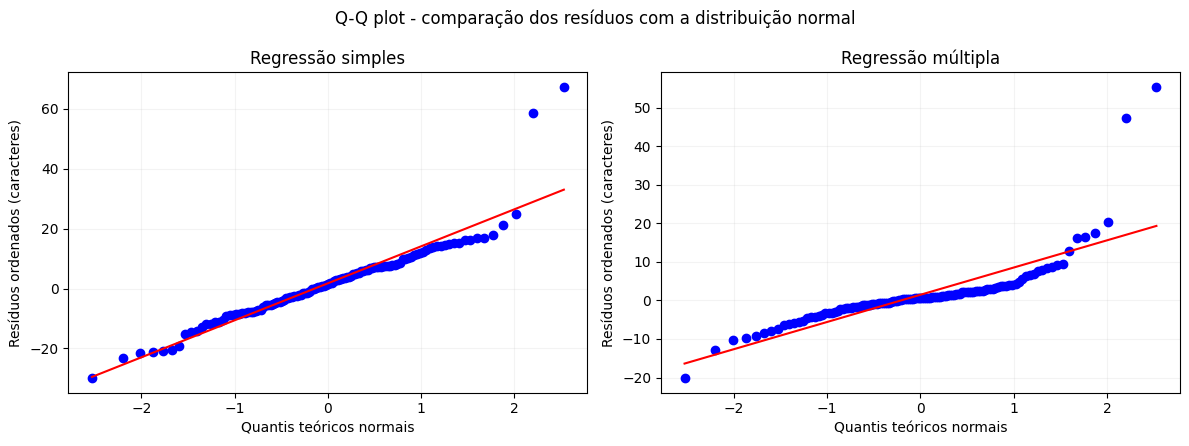

,skew,median
modelo,,
linear_multipla,3.436,0.601
linear_simples,1.480,1.669
media_treino,6.625,-91.255


,row_id,modelo,observado,previsto,residuo,erro_absoluto
23,387,media_treino,2960,191.255187,2768.744813,2768.744813
5,597,media_treino,2805,191.255187,2613.744813,2613.744813
61,380,media_treino,1102,191.255187,910.744813,910.744813
77,600,media_treino,773,191.255187,581.744813,581.744813
76,309,media_treino,406,191.255187,214.744813,214.744813
46,383,media_treino,398,191.255187,206.744813,206.744813


In [7]:
display(figures[2])
display(predictions.groupby('modelo').residuo.agg(['skew','median']).round(3))
display(predictions.assign(erro_absoluto=lambda d:d.residuo.abs()).sort_values('erro_absoluto',ascending=False).head(6))

**Interpretação - Q-Q:** pontos próximos da reta são compatíveis visualmente com quantis normais;
desvios nas caudas alertam para extremos e assimetria. Não assumimos normalidade só por usar regressão.
Normalidade dos erros não é requisito para calcular previsões OLS, mas importa para a inferência
paramétrica usual. Não apresentamos intervalos ou testes de coeficientes baseados nessa premissa.

**Resultado observado:** a região central da regressão simples acompanha aproximadamente a reta, mas a cauda superior se afasta acentuadamente. A múltipla tem concentração central mais estreita e também cauda positiva pronunciada. Os gráficos não sustentam assumir resíduos normalmente distribuídos sem investigação adicional; não foram feitos testes formais de normalidade ou inferência sobre os coeficientes.

## 6. Limitações e próximos passos
- A regressão prevê um número contínuo, sem limites de classe; pode gerar comprimento negativo.
  Intenções e tipos de ameaça são categorias nominais: codificá-las como 0, 1, 2 imporia uma ordem
  e distâncias inexistentes. Arredondar a previsão não resolve isso, nem produz probabilidades calibradas.
- Os atributos e o alvo vêm do mesmo texto. O exercício aproxima uma medida diretamente calculável,
  não substitui `len(text)` em produção. R² alto pode refletir redundância estrutural, não semântica.
- Amostra pequena, em inglês, proveniência/licença incompletas, possível dependência entre mensagens
  e classes sobrepostas limitam generalização. A divisão por mensagem não garante independência por
  autor/template, pois essa informação não está disponível.
- O TP2 encontrou p≈0,1912 para comprimento de Phishing versus benigno: não rejeição de H₀ não prova
  igualdade, nem impossibilidade de classificação por conteúdo. O resultado tampouco justifica limiar de tamanho.
- O classificador futuro terá TF-IDF e regressão logística como candidato principal, SVM linear como
  comparação planejada, validação por classe e análise de Phishing/Pretexting. Nenhum foi treinado aqui.
- Ver `reports/TP3/pergunta_classificacao.md` e `planejamento_T2.md`. Precisamos validar em dados
  independentes e bancários em português antes de integrar o modelo ao agente.

## Referências técnicas
- [Pipeline e prevenção de vazamento](https://scikit-learn.org/stable/common_pitfalls.html)
- [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [RMSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)
- [Q-Q com scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html)